# 02 — Préparation des données et feature engineering

**Projet 6 OpenClassrooms — Modèle de scoring crédit « Prêt à dépenser »**

**Objectif** : produire un jeu de données **propre, fusionné et enrichi**, avec une ligne par client, prêt pour l'entraînement (résultat attendu de l'étape 1).

**Méthode** : on s'appuie sur le kernel Kaggle [LightGBM with Simple Features](https://www.kaggle.com/code/jsaguiar/lightgbm-with-simple-features/script) (jsaguiar).


Le code est rangé dans `src/feature_engineering_functions.py`, sur le modèle des modules de fonctions des screencasts du cours (`feature_engineering_functions`, `data_processing_functions`, `settings.py`).


- Passer de l'analyse exploratoire des données (EDA) à une logique de construction du ey de dibbées destibée au modè§le de scroing crédit.



In [2]:
# -------------------------- Imports --------------------------
import sys

sys.path.append("..")

import gc
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

sns.set()

from src.settings import (
    FEATURES_USED_FILE,
    FIGURES_PATH,
    ID_COLUMN,
    NEW_CLIENTS_FILE,
    PROCESSED_DATA_PATH,
    TARGET,
    TEST_FILE,
    TEST_SIZE,
    TRAIN_FILE,
    random_state,
)
from src.data_processing_functions import (
    clean_column_names,
    missing_values_table,
    replace_infinite_values,
)
from src.feature_engineering_functions import build_features

PROCESSED_DATA_PATH.mkdir(parents=True, exist_ok=True)
FIGURES_PATH.mkdir(parents=True, exist_ok=True)

## 1. Construction des features (agrégations + jointures)

**Pourquoi agréger ?** Un modèle de classification attend **une ligne par individu**. Or un client a en moyenne 5 crédits au bureau, 5 demandes passées, environ 40 échéances de remboursement... On résume donc chaque historique par des statistiques (min, max, moyenne, somme, variance) : par exemple `INSTAL_DPD_MEAN` est le **nombre moyen de jours de retard** du client sur ses remboursements passés.

Les jointures sont faites **à gauche** sur `SK_ID_CURR`, et la fonction **vérifie après chaque jointure que le nombre de lignes n'a pas changé** (point de vigilance de la consigne : « fusionner sans gérer les duplications ou pertes de lignes »).

> Durée : quelques minutes (environ 60 millions de lignes à agréger).

In [3]:
start = time.time()
df = build_features()
print(f"\nDurée : {time.time() - start:.0f} s | Mémoire : {df.memory_usage().sum() / 1024**2:.0f} Mo")

application_train.csv : 307,511 lignes x 122 colonnes
application_test.csv : 48,744 lignes x 121 colonnes
Lignes supprimées (CODE_GENDER = XNA) : 4
Table principale : (356251, 248)
bureau.csv : 1,716,428 lignes x 17 colonnes
bureau_balance.csv : 27,299,925 lignes x 3 colonnes
+ bureau                  116 features | clients couverts : 85.8%
previous_application.csv : 1,670,214 lignes x 37 colonnes
+ previous_applications   249 features | clients couverts : 95.1%
POS_CASH_balance.csv : 10,001,358 lignes x 8 colonnes
+ pos_cash                 18 features | clients couverts : 94.7%
installments_payments.csv : 13,605,401 lignes x 8 colonnes
+ installments             26 features | clients couverts : 95.3%
credit_card_balance.csv : 3,840,312 lignes x 23 colonnes
+ credit_card             141 features | clients couverts : 29.1%
Dataset final : (356251, 798)

Durée : 48 s | Mémoire : 910 Mo


Objectif : constituer un dataset enrichir avec une ligne par client 


122 colonnes -> 798 var

307 k obs + 48 k obs = 356k obs 

Les cinq blocs apportent 550 features au total. Les 248 colonnes de la table principale, auxquelles s'ajoutent ces 550 variables, donnent bien les 798 colonnes finales.

Proportion des clients pour lesquels le bloc historique apporte des informations.

Par exemple :
- previous_applications couvre 95,1 % des clients.
- bureau couvre 85,8 % des clients.
- credit_card ne couvre que 29,1 % des clients.



les étapes de l'agrégation sont les suivantes

| Étape | Fichiers | Méthode |
|---|---|---|
| 1. Table principale | `application_train` + `application_test` | Empilement vertical des clients avec `pd.concat`, puis encodage et création de cinq ratios |
| 2. Bureau de crédit | `bureau` + `bureau_balance` | Agrégation des mois par crédit (`SK_ID_BUREAU`), puis des crédits par client (`SK_ID_CURR`) |
| 3. Demandes précédentes | `previous_application` | Agrégation par client, avec statistiques séparées sur les demandes acceptées et refusées |
| 4. Prêts à la consommation | `POS_CASH_balance` | Agrégation des observations mensuelles par client |
| 5. Remboursements | `installments_payments` | Calcul des retards et écarts de paiement, puis agrégation par client |
| 6. Cartes de crédit | `credit_card_balance` | Calcul de statistiques descriptives par client |

In [4]:
print("Dimensions :", df.shape)

print("Identifiants dupliqués :",
      df["SK_ID_CURR"].duplicated().sum())

print("Clients avec TARGET renseigné :",
      df["TARGET"].notna().sum())

print("Clients sans TARGET :",
      df["TARGET"].isna().sum())

print("Colonnes entièrement manquantes :",
      df.isna().all().sum())

print("Variables numériques :",
      df.select_dtypes(include="number").shape[1])

Dimensions : (356251, 798)
Identifiants dupliqués : 0
Clients avec TARGET renseigné : 307507
Clients sans TARGET : 48744
Colonnes entièrement manquantes : 0
Variables numériques : 798


## 2. Nettoyage final et contrôles qualité

In [5]:
df = replace_infinite_values(df)
df = clean_column_names(df)

assert df[ID_COLUMN].is_unique, "SK_ID_CURR doit rester unique"
assert "index" not in df.columns
print(f"Dimensions : {df.shape}")
print(f"Doublons de lignes : {df.duplicated().sum()}")
print("Types :", df.dtypes.astype(str).value_counts().to_dict())

61 valeurs infinies remplacées par NaN
Dimensions : (356251, 798)
Doublons de lignes : 0
Types : {'float32': 622, 'uint8': 137, 'int8': 36, 'int16': 2, 'int32': 1}


## 3. Séparation des jeux de données

On distingue trois jeux :

| Jeu | Origine | Usage |
|---|---|---|
| **train** (80 %) | `application_train` | Validation croisée, optimisation des hyperparamètres et du seuil |
| **test** (20 %) | `application_train` | **Évaluation finale uniquement**, jamais utilisé pour faire un choix |
| **new_clients** | `application_test` (sans cible) | Simulation de « nouveaux clients » : serving MLflow, API, suivi de dérive |

La validation croisée sert à **choisir** (modèle, hyperparamètres, seuil). Chaque choix « consomme » un peu de l'information des plis de validation, donc le score de CV du meilleur modèle est optimiste. Le jeu de test, jamais vu, donne une estimation **non biaisée** de la performance en production

Le découpage est **stratifié** sur la cible pour garder 8,07 % de défauts dans chaque jeu.

In [6]:
labelled = df[df[TARGET].notna()].copy()
new_clients = df[df[TARGET].isna()].drop(columns=[TARGET]).copy()
labelled[TARGET] = labelled[TARGET].astype(np.int8)
del df
gc.collect()

train, test = train_test_split(
    labelled, test_size=TEST_SIZE, stratify=labelled[TARGET], random_state=random_state
)
del labelled
gc.collect()

for name, data in [("train", train), ("test", test)]:
    print(f"{name:<12} {data.shape[0]:>7,} lignes | taux de défaut : {data[TARGET].mean():.2%}")
print(f"{'new_clients':<12} {new_clients.shape[0]:>7,} lignes | cible inconnue")

train        246,005 lignes | taux de défaut : 8.07%
test          61,502 lignes | taux de défaut : 8.07%
new_clients   48,744 lignes | cible inconnue


## 4. Sélection des features

(calculée sur le train uniquement)

Le kernel produit plus de 750 features. On applique trois filtres simples.
### 4.1 Features constantes
Une colonne qui ne prend qu'une seule valeur n'apporte aucune information.

In [7]:
candidate_features = [c for c in train.columns if c not in (ID_COLUMN, TARGET)]
n_unique = train[candidate_features].nunique(dropna=False)
constant_features = n_unique[n_unique <= 1].index.tolist()
print(f"{len(constant_features)} features constantes supprimées :")
print(constant_features)
features = [c for c in candidate_features if c not in constant_features]

0 features constantes supprimées :
[]


### 4.2 Valeurs manquantes :

mesure

616 features sur 796 ont des valeurs manquantes


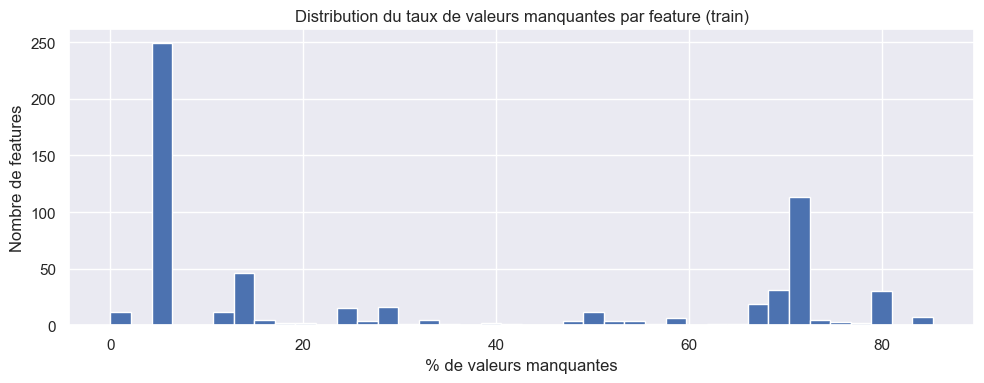

,nb_manquants,pct_manquants,dtype
REFUSED_RATE_DOWN_PAYMENT_MEAN,209866,85.309648,float32
REFUSED_RATE_DOWN_PAYMENT_MAX,209866,85.309648,float32
REFUSED_RATE_DOWN_PAYMENT_MIN,209866,85.309648,float32
REFUSED_AMT_DOWN_PAYMENT_MEAN,209866,85.309648,float32
REFUSED_AMT_DOWN_PAYMENT_MAX,209866,85.309648,float32
REFUSED_AMT_DOWN_PAYMENT_MIN,209866,85.309648,float32
REFUSED_APP_CREDIT_PERC_VAR,206734,84.036503,float32
CC_AMT_PAYMENT_CURRENT_VAR,197451,80.263003,float32
CC_AMT_DRAWINGS_OTHER_CURRENT_VAR,197378,80.233329,float32
CC_AMT_DRAWINGS_ATM_CURRENT_VAR,197378,80.233329,float32


In [8]:
missing_features = missing_values_table(train[features])
print(f"{len(missing_features)} features sur {len(features)} ont des valeurs manquantes")

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(missing_features["pct_manquants"], bins=40)
ax.set_xlabel("% de valeurs manquantes")
ax.set_ylabel("Nombre de features")
ax.set_title("Distribution du taux de valeurs manquantes par feature (train)")
plt.tight_layout()
plt.savefig(FIGURES_PATH / "02_missing_rate_distribution.png", dpi=100)
plt.show()

missing_features.head(10)

**Pourquoi on ne supprime pas ces colonnes** : les taux de manquants élevés viennent surtout des **agrégats des tables à faible couverture** (cartes de crédit : 28 % des clients ; demandes refusées : une partie seulement des clients). Pour ces features, `NaN` signifie « le client n'a pas ce type d'historique », ce qui est une information en soi. LightGBM l'exploite directement ; pour les autres modèles, l'imputation sera faite dans le `Pipeline` de validation croisée.

### 4.3 Features redondantes (corrélation > 0,95)

On retir les var quasi idnetiques à une autres. exemple prix du bien et montant du crédit, ou les version AVG, MEDI, MODE d'une même caractéristiques du logement

Avec plus de 700 features, on automatise : pour chaque paire corrélée à plus de 0,95 (en valeur absolue), on **garde la feature la plus complète** (le moins de `NaN`). La corrélation est calculée sur un échantillon de 30 000 clients du train pour limiter le temps de calcul.



In [9]:
CORRELATION_THRESHOLD = 0.95

sample = train[features].sample(30_000, random_state=random_state)
start = time.time()
corr_matrix = sample.corr(min_periods=1000).abs()
print(f"Matrice de corrélation {corr_matrix.shape} calculée en {time.time() - start:.0f} s")

# On parcourt les features de la plus complète à la moins complète
missing_rate = train[features].isna().mean()
ordered_features = missing_rate.sort_values(kind="stable").index.tolist()

kept, redundant_pairs = [], []
for feature in ordered_features:
    correlated_with_kept = corr_matrix.loc[feature, kept]
    correlated_with_kept = correlated_with_kept[correlated_with_kept > CORRELATION_THRESHOLD]
    if correlated_with_kept.empty:
        kept.append(feature)
    else:
        redundant_pairs.append((feature, correlated_with_kept.idxmax(), correlated_with_kept.max()))

redundant = pd.DataFrame(redundant_pairs, columns=["feature_supprimee", "redondante_avec", "corr_abs"])
print(f"{len(redundant)} features redondantes supprimées, {len(kept)} conservées")
redundant.head(15)

Matrice de corrélation (796, 796) calculée en 21 s
137 features redondantes supprimées, 659 conservées


,feature_supprimee,redondante_avec,corr_abs
0,REGION_RATING_CLIENT_W_CITY,REGION_RATING_CLIENT,0.954497
1,NAME_CONTRACT_TYPE_Revolving_loans,NAME_CONTRACT_TYPE_Cash_loans,1.000000
2,NAME_INCOME_TYPE_Pensioner,FLAG_EMP_PHONE,0.999437
3,ORGANIZATION_TYPE_XNA,FLAG_EMP_PHONE,0.999887
4,DAYS_EMPLOYED_ANOM,FLAG_EMP_PHONE,0.999887
5,AMT_GOODS_PRICE,AMT_CREDIT,0.986932
6,OBS_60_CNT_SOCIAL_CIRCLE,OBS_30_CNT_SOCIAL_CIRCLE,0.998364
7,INSTAL_AMT_PAYMENT_SUM,INSTAL_AMT_INSTALMENT_SUM,0.982154
8,INSTAL_AMT_PAYMENT_MAX,INSTAL_AMT_INSTALMENT_MAX,0.999221
9,INSTAL_AMT_PAYMENT_MEAN,INSTAL_AMT_INSTALMENT_MEAN,0.974507


**Lecture des redondances**
- Beaucoup de redondances sont **mécaniques** : les deux modalités d'une variable binaire après one-hot (`Cash_loans` / `Revolving_loans`), ou montant demandé et montant accordé (`PREV_AMT_APPLICATION` / `PREV_AMT_CREDIT`), échéance due et payée (`INSTAL_AMT_INSTALMENT` / `INSTAL_AMT_PAYMENT`).
- `DAYS_EMPLOYED_ANOM`, `NAME_INCOME_TYPE_Pensioner` et `ORGANIZATION_TYPE_XNA` sont retirées car **quasiment identiques à `FLAG_EMP_PHONE`** (corrélation 0,9999) : un retraité n'a ni employeur ni téléphone professionnel. **L'information « retraité / sans emploi » est donc conservée** via `FLAG_EMP_PHONE` (= 1 − `DAYS_EMPLOYED_ANOM`).
- Si on change le plancher de corr à la baisse pour le passer à 0,75 le nombre de redondances augmentera beaucoup 

In [10]:
features_used = [f for f in features if f in set(kept)]  # ordre d'origine des colonnes
del sample, corr_matrix
gc.collect()
print(f"Features avant filtrage : {len(candidate_features)}")
print(f"  - constantes          : {len(constant_features)}")
print(f"  - redondantes         : {len(redundant)}")
print(f"Features retenues       : {len(features_used)}")

Features avant filtrage : 796
  - constantes          : 0
  - redondantes         : 137
Features retenues       : 659


## 5. Validation de la qualité des features

Avant de modéliser, on vérifie que les features construites portent bien un signal. Mesure simple et robuste au déséquilibre : l'**AUC univariée**, c'est-à-dire l'AUC obtenue en utilisant **une seule feature comme score**.

Elle mesure la capaicté d'un midèle ou d'une var à distinguer des classes. Ici il s'afit de distinguer les clients qui recontrent des difficultés de relboursement (TARGUET =1) de ceux qui n'en recontreront pas (TARGET = 0)
- AUC = 0,5 : aucun pouvoir discriminant (hasard) ;
- AUC éloignée de 0,5 (au-dessus ou en dessous) : la feature sépare bons et mauvais clients. On affiche donc `max(AUC, 1 − AUC)`.

Calcul sur le train uniquement (échantillon de 60 000 clients), en ignorant les `NaN` de chaque feature.

In [11]:
auc_sample = train.sample(60_000, random_state=random_state)
univariate = []
for feature in features_used:
    values = auc_sample[feature]
    mask = values.notna()
    y_feature = auc_sample.loc[mask, TARGET]
    if mask.sum() < 1000 or y_feature.nunique() < 2 or values[mask].nunique() < 2:
        continue
    auc = roc_auc_score(y_feature, values[mask])
    univariate.append({
        "feature": feature,
        "auc_univariee": max(auc, 1 - auc),
        "sens": "risque ↑ quand valeur ↑" if auc > 0.5 else "risque ↓ quand valeur ↑",
        "pct_renseigne": round(100 * mask.mean(), 1),
    })
univariate = pd.DataFrame(univariate).sort_values("auc_univariee", ascending=False)
univariate.head(25).reset_index(drop=True)

,feature,auc_univariee,sens,pct_renseigne
0,EXT_SOURCE_3,0.680764,risque ↓ quand valeur ↑,80.1
1,EXT_SOURCE_1,0.663740,risque ↓ quand valeur ↑,43.7
2,EXT_SOURCE_2,0.656224,risque ↓ quand valeur ↑,99.8
3,CC_CNT_DRAWINGS_CURRENT_VAR,0.635358,risque ↑ quand valeur ↑,27.8
4,CC_CNT_DRAWINGS_CURRENT_MEAN,0.632829,risque ↑ quand valeur ↑,28.0
5,CC_CNT_DRAWINGS_CURRENT_MAX,0.625948,risque ↑ quand valeur ↑,28.0
6,CC_AMT_DRAWINGS_CURRENT_MEAN,0.614695,risque ↑ quand valeur ↑,28.0
7,CC_AMT_BALANCE_MEAN,0.611642,risque ↑ quand valeur ↑,28.0
8,CC_CNT_DRAWINGS_CURRENT_SUM,0.608633,risque ↑ quand valeur ↑,28.0
9,CC_AMT_DRAWINGS_CURRENT_VAR,0.608291,risque ↑ quand valeur ↑,27.8


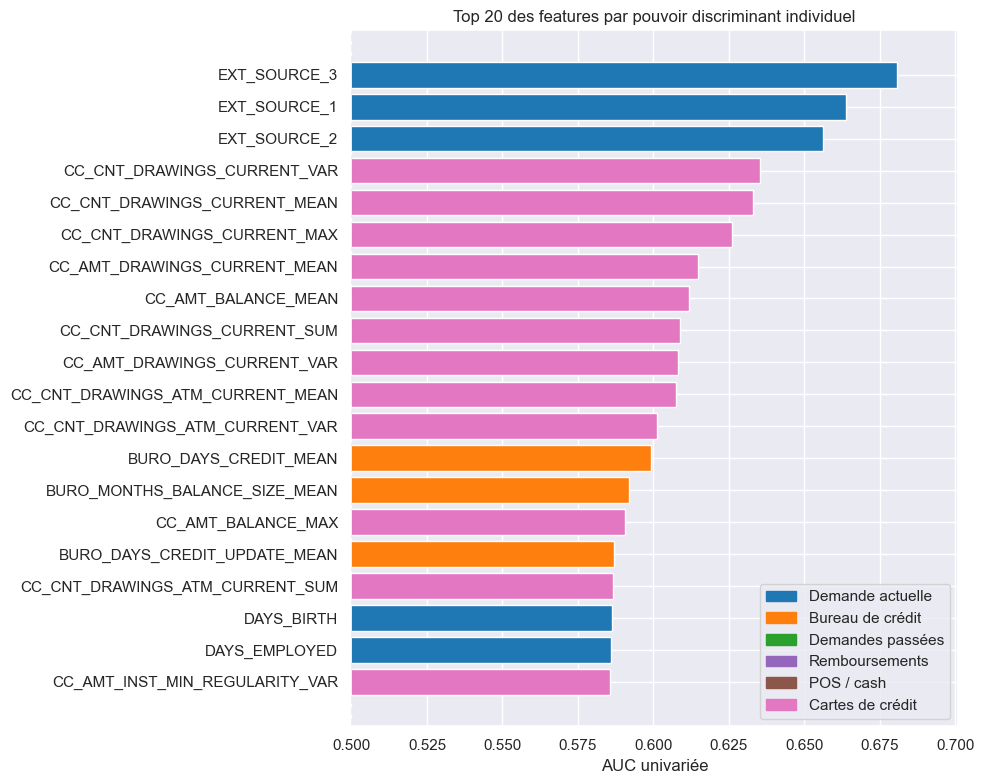

Parmi les 50 features les plus discriminantes, 44 sont des features créées


In [12]:
top = univariate.head(20).iloc[::-1]
source_colors = {
    "BURO": "tab:orange", "ACTIVE": "tab:orange", "CLOSED": "tab:orange",
    "PREV": "tab:green", "APPROVED": "tab:green", "REFUSED": "tab:green",
    "INSTAL": "tab:purple", "POS": "tab:brown", "CC": "tab:pink",
}
colors = [source_colors.get(f.split("_")[0], "tab:blue") for f in top["feature"]]

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(top["feature"], top["auc_univariee"], color=colors)
ax.axvline(0.5, color="grey", linestyle="--")
ax.set_xlim(0.5, top["auc_univariee"].max() + 0.02)
ax.set_xlabel("AUC univariée")
ax.set_title("Top 20 des features par pouvoir discriminant individuel")
from matplotlib.patches import Patch
legend_items = [
    ("Demande actuelle", "tab:blue"), ("Bureau de crédit", "tab:orange"),
    ("Demandes passées", "tab:green"), ("Remboursements", "tab:purple"),
    ("POS / cash", "tab:brown"), ("Cartes de crédit", "tab:pink"),
]
ax.legend(handles=[Patch(color=c, label=l) for l, c in legend_items], loc="lower right")
plt.tight_layout()
plt.savefig(FIGURES_PATH / "02_univariate_auc_top20.png", dpi=100)
plt.show()

created_prefixes = ("BURO_", "ACTIVE_", "CLOSED_", "PREV_", "APPROVED_", "REFUSED_",
                    "POS_", "INSTAL_", "CC_")
created_ratios = ("DAYS_EMPLOYED_PERC", "INCOME_CREDIT_PERC", "INCOME_PER_PERSON",
                  "ANNUITY_INCOME_PERC", "PAYMENT_RATE", "DAYS_EMPLOYED_ANOM")
n_created_top50 = sum(
    f.startswith(created_prefixes) or f in created_ratios for f in univariate.head(50)["feature"]
)
print(f"Parmi les 50 features les plus discriminantes, {n_created_top50} sont des features créées")

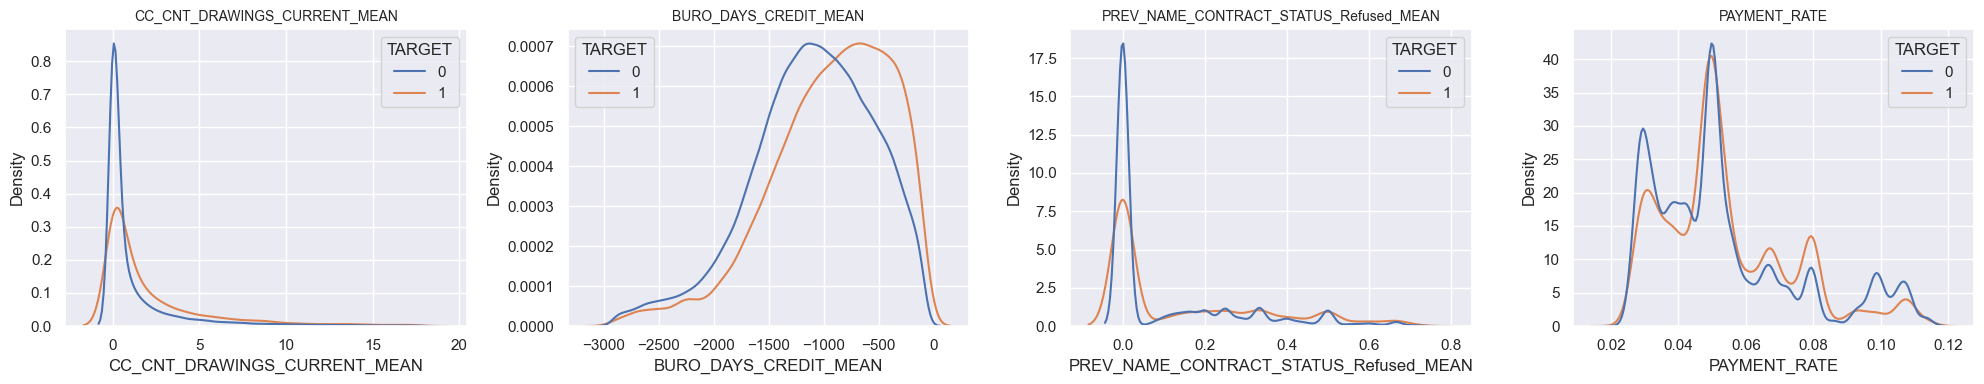

In [13]:
features_to_plot = ["CC_CNT_DRAWINGS_CURRENT_MEAN", "BURO_DAYS_CREDIT_MEAN",
                    "PREV_NAME_CONTRACT_STATUS_Refused_MEAN", "PAYMENT_RATE"]
features_to_plot = [f for f in features_to_plot if f in train.columns]

fig, axes = plt.subplots(1, len(features_to_plot), figsize=(5 * len(features_to_plot), 4))
for ax, feature in zip(axes, features_to_plot):
    data = train[[feature, TARGET]].dropna()
    upper = data[feature].quantile(0.99)  # on coupe les 1 % extrêmes pour la lisibilité
    sns.kdeplot(data=data[data[feature] <= upper], x=feature, hue=TARGET,
                common_norm=False, ax=ax)
    ax.set_title(feature, fontsize=10)
plt.tight_layout()
plt.savefig(FIGURES_PATH / "02_kde_engineered_features.png", dpi=100)
plt.show()

- Les scores externes EXT_SOURCE_1, EXT_SOURCE_2 et EXT_SOURCE_3 présentent le pouvoir discriminant individuel le plus élevé, avec des AUC comprises entre 0,66 et 0,68. Ils constituent les meilleurs indicateurs isolés du risque de défaut. Toutefois, la majorité des variables du top 20 proviennent du feature engineering, ce qui confirme l'intérêt d'exploiter les historiques de crédit et de construire des indicateurs agrégés.

- Les variables issues des cartes de crédit (CC_*) occupent une place prépondérante : 11 des 20 premières variables concernent les cartes de crédit. Elles décrivent principalement :

  - La fréquence des tirages sur les cartes (CC_CNT_DRAWINGS_CURRENT_MEAN, MAX, VAR, SUM) : les clients défaillants présentent une distribution davantage étalée vers les valeurs élevées, ce qui suggère qu'un recours plus fréquent au crédit renouvelable est associé à un risque accru.

  - Les montants mobilisés et les encours (CC_AMT_DRAWINGS_CURRENT_MEAN, CC_AMT_BALANCE_MEAN, MAX) : ces indicateurs renseignent sur l'intensité de l'utilisation du crédit. Leur pouvoir discriminant peut refléter des besoins de financement ou des tensions de trésorerie, sans permettre d'établir une relation causale.

  - La variabilité des comportements (*_VAR) : les fluctuations du nombre de tirages ou des montants utilisés apportent également un signal prédictif. Un comportement de crédit irrégulier peut ainsi contribuer à différencier les profils de risque.

- L'historique au bureau de crédit (BURO_*) constitue une deuxième famille importante de variables discriminantes.

    - BURO_DAYS_CREDIT_MEAN (AUC proche de 0,60) mesure l'ancienneté moyenne des crédits externes, exprimée en jours négatifs avant la demande actuelle. La distribution des clients défaillants est décalée vers des valeurs moins négatives : des crédits en moyenne plus récents sont associés à un risque de défaut plus élevé.

    - BURO_MONTHS_BALANCE_SIZE_MEAN et BURO_DAYS_CREDIT_UPDATE_MEAN apportent des informations complémentaires sur la profondeur et l'actualisation de l'historique de crédit.

Ces résultats montrent que la temporalité des engagements financiers constitue un facteur discriminant, même lorsqu'elle est considérée indépendamment des montants empruntés.

- L'âge et l'ancienneté professionnelle conservent un pouvoir explicatif individuel, avec DAYS_BIRTH et DAYS_EMPLOYED présentant des AUC proches de 0,59. Les clients plus jeunes et ceux ayant une ancienneté professionnelle plus faible tendent à présenter davantage de difficultés de remboursement. Ces variables restent néanmoins moins discriminantes individuellement que les scores externes ou certains indicateurs de cartes de crédit.

Les refus de crédit antérieurs et les incidents de remboursement fournissent également un signal prédictif.

- PREV_NAME_CONTRACT_STATUS_Refus ed_MEAN représente la proportion des demandes précédentes refusées. Sa distribution est fortement concentrée autour de zéro, mais les clients défaillants présentent davantage de valeurs positives, suggérant qu'un historique de refus est associé à un risque supérieur.

- INSTAL_DPD_MEAN mesure le nombre moyen de jours de retard de paiement. Une AUC d'environ 0,56, si elle est confirmée par le classement complet, indique un signal discriminant modeste mais cohérent avec l'analyse traditionnelle du risque de crédit : les incidents passés peuvent renseigner sur les difficultés futures.

- Le ratio PAYMENT_RATE (annuité / montant du crédit) présente des distributions très proches entre les deux classes, avec plusieurs concentrations communes. Il ne semble donc pas permettre une séparation visuelle aussi nette que certaines variables précédentes. Son utilité pourrait toutefois apparaître lorsqu'il est combiné à d'autres indicateurs, notamment les revenus, l'endettement et les historiques de remboursement.


**Deux limites de l'AUC univariée, à garder en tête**
1. **Biais de couverture** : l'AUC est calculée sur les clients renseignés. Pour les features `CC_` (environ 28 % des clients), elle mesure le pouvoir discriminant **parmi les détenteurs de carte**, pas sur l'ensemble.
2. **Elle ne capte que les relations monotones** : `PAYMENT_RATE` n'a qu'une AUC de 0,54, alors que le notebook 01 a montré un signal fort mais **non monotone** (le risque monte puis chute au dernier décile).

3. Enfin, aucune feature isolée ne dépasse une AUC de 0,7 : la performance viendra de leur **combinaison**. En référence, le premier du challenge Kaggle atteint 0,80 à 0,82 ; au-delà, il faudra suspecter du surapprentissage ou une fuite de données.

## 6. Sauvegarde

- Jeux de données au format **Parquet** et se lit 10 à 20 fois plus vite qu'un CSV.
- Liste des features retenues dans `features_used.json`, **versionnée sur GitHub** : elle sera loggée dans MLflow avec chaque run, pour la traçabilité.
- cration de 4 fichiers :

In [14]:
columns_to_save = [ID_COLUMN, TARGET] + features_used
train[columns_to_save].to_parquet(TRAIN_FILE, index=False)
test[columns_to_save].to_parquet(TEST_FILE, index=False)
new_clients[[ID_COLUMN] + features_used].to_parquet(NEW_CLIENTS_FILE, index=False)

with open(FEATURES_USED_FILE, "w") as f:
    json.dump(features_used, f, indent=2)

for path in [TRAIN_FILE, TEST_FILE, NEW_CLIENTS_FILE]:
    print(f"{path.name:<22} {path.stat().st_size / 1024**2:>6.0f} Mo")
print(f"{FEATURES_USED_FILE.name:<22} {len(features_used)} features")

train.parquet             118 Mo
test.parquet               31 Mo
new_clients.parquet        26 Mo
features_used.json     659 features


Pour comparer correctement les modèles, il faut savoir quelles variables exactes ont été utilisées lors de chaque entraînement.

C'est le rôle de features_used.json.
- GitHub permet de conserver l'historique des modifications du fichier, à condition de le suivre avec Git et de réaliser des commits.
- MLflow pourra enregistrer ce JSON comme artifact associé à chaque expérience, afin de retrouver la configuration du modèle.

## 7. Bilan de l'étape 1

**Résultat** : un jeu de données propre, fusionné et enrichi, avec une ligne par client, découpé en train / test stratifiés, et une liste de features documentée.

**Fiche d'autoévaluation, étape 1**
- ✅ Données brutes explorées, formats identifiés, valeurs manquantes, doublons et jointures contrôlés (notebooks 01 et 02).
- ✅ Features pertinentes construites par agrégats et transformations (kernel jsaguiar adapté).
- ✅ Qualité des features validée par visualisations et statistiques (AUC univariée, distributions par classe).
- ✅ Déséquilibre des classes identifié (8,07 %) : stratification en place ; pondération et coût métier à l'étape de modélisation.



La prochaine étape sera de tester plusieurs modèles avec validation croisée et des métriques adaptées : **notebook 03**, avec tracking MLflow (étapes 2 et 3).
